# Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
# from google.colab import drive
%reload_ext autoreload
%autoreload 2
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from tqdm.notebook import tqdm
from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix

from tqdm.notebook import tqdm

ModuleNotFoundError: No module named 'ipywidgets'

In [24]:
from sklearn.decomposition import PCA

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
# import torchvision
# import torchvision.datasets as datasets
from torch.utils.data import DataLoader
# import torchvision.transforms as transforms
# from torch.utils.tensorboard import SummaryWriteR

In [25]:
sns.set_theme()

In [26]:
RANDOM_SEED = 99
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Download CIC IDS 2017

[Este](https://www.unb.ca/cic/datasets/ids-2017.html) conjunto de dados contém informações sobre fluxos de rede, representando tanto o tráfego benigno quanto ataques populares. Para o ambiente de teste desta coleta de dados, uma rede foi configurada para o atacante e uma rede separada foi configurada para as vítimas, esta última contendo firewalls, roteadores, switches, servidores e estações de trabalho em execução em diferentes versões dos sistemas operacionais Windows e Linux. Para gerar o tráfego benigno, os autores utilizaram um sistema desenvolvido por eles mesmos, que então extraiu o comportamento abstrato de 25 usuários com base em diferentes protocolos de aplicação. Os dados foram coletados ao longo de cinco dias de atividade de rede e foram processados para extrair mais de 80 features do conjunto de dados usando a ferramenta CICFlowMeter8.


In [ ]:
# # update gdown version
# !pip install --upgrade --no-cache-dir gdown

In [ ]:
# !wget 'http://205.174.165.80/CICDataset/CIC-IDS-2017/Dataset/MachineLearningCSV.zip' -O CIC_IDS_2017.zip
!gdown '1X9s72a_9VzukVbFhGKHW1xLnyrnqu3MP' -O CIC_IDS_2017.zip

Downloading...
From (original): https://drive.google.com/uc?id=1X9s72a_9VzukVbFhGKHW1xLnyrnqu3MP
From (redirected): https://drive.google.com/uc?id=1X9s72a_9VzukVbFhGKHW1xLnyrnqu3MP&confirm=t&uuid=72e1d136-a3b8-482d-baa0-0fc0e8468f64
To: /content/CIC_IDS_2017.zip
100% 235M/235M [00:03<00:00, 59.1MB/s]


In [ ]:
# !unzip MachineLearningCSV.zip
!unzip CIC_IDS_2017.zip

Archive:  CIC_IDS_2017.zip
   creating: MachineLearningCVE/
  inflating: MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv  
  inflating: MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv  
  inflating: MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  
  inflating: MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  
  inflating: MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv  
  inflating: MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv  
  inflating: MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv  
  inflating: MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv  


# Carregando os dados

In [27]:
df_list = []
for file in os.listdir('data/CIC_IDS_2017'):
  df_aux = pd.read_csv(f'data/CIC_IDS_2017/{file}')
  df_list.append(df_aux)
df = pd.concat(df_list, ignore_index=True)

Algumas colunas tem seus nomes iniciados com espaços ou finalizados com espaços. Vamos remover esses espaços não úteis para ajustar o nome das colunas.

In [28]:
df.columns = df.columns.str.strip()

# Limpando os dados

É necessário limpar os dados realizando:
- Descarte de registros duplicados
- Descarte de registros com valores NaN (Not a Number)/ Null / NA (Not Available)
- Evitar registros com valores não finitos. Nesse caso, uma abordagem válida é substituirmos os mesmos pelo maior valor finito presente no dataset.

Registros duplicados

In [29]:
# Descartando duplicadas
initial_len = df.shape[0]
df = df.drop_duplicates()
print(f'Tamanho inicial: {initial_len}, tamanho final {df.shape[0]} | Descartadas {initial_len - df.shape[0]} duplicadas')

Tamanho inicial: 2830743, tamanho final 2522362 | Descartadas 308381 duplicadas


Registros com valores Null/NaN/NA

In [30]:
# Descartando registros com valores NaN/Null/NA
initial_len = df.shape[0]
df = df.dropna()
print(f'Tamanho inicial: {initial_len}, tamanho final {df.shape[0]} | Descartados {initial_len - df.shape[0]} registros com valores NA')

Tamanho inicial: 2522362, tamanho final 2522009 | Descartados 353 registros com valores NA


In [31]:
df = df.reset_index(drop=True)

Registros com valores não finitos

In [32]:
# Evitando registros com valores não finitos
max_finite_flow_packets_per_sec = df[np.isfinite(df['Flow Packets/s'])]['Flow Packets/s'].max()
max_finite_flow_bytes_per_sec = df[np.isfinite(df['Flow Bytes/s'])]['Flow Bytes/s'].max()

df.loc[df['Flow Packets/s'] == np.inf, 'Flow Packets/s'] = max_finite_flow_packets_per_sec
df.loc[df['Flow Bytes/s'] == np.inf, 'Flow Bytes/s'] = max_finite_flow_bytes_per_sec

# Dividindo dados nos conjuntos de treino, validação e teste

**Conjunto de treino**

Para a detecção de anomalias, vamos usar somente os dados que representam o tráfego benigno para o conjunto de treino. Dessa forma, os algoritmos serão capazes de identificar padrões e desvios em relação ao comportamento normal (benigno) dos dados.

**Conjuntos de validação e teste**

Porém, devem ser incluídos dados que representam o tráfego maliciosos nos conjuntos de validação e teste. Esses dados maliciosos no conjunto de validação são importantes para que possamos definir um *threshold* para que seja possível detectar anomalias. Além disso, os dados maliciosos também precisam ser incluídos no conjunto de teste para que possamos avaliar o desempenho do nosso modelo.

In [33]:
df_train = df.query('Label == "BENIGN"').sample(frac=0.6, random_state=RANDOM_SEED)
df_val_test = df.drop(df_train.index)

df_train = df_train.reset_index(drop=True)
df_val_test = df_val_test.reset_index(drop=True)

X_train = df_train.drop('Label', axis='columns')

In [34]:
X_val, X_test, classes_val, classes_test = train_test_split(df_val_test.drop('Label', axis='columns'), df_val_test['Label'], test_size=0.65, stratify=df_val_test['Label'], random_state=RANDOM_SEED)

X_val, X_test = X_val.reset_index(drop=True), X_test.reset_index(drop=True)
classes_val, classes_test =  classes_val.reset_index(drop=True), classes_test.reset_index(drop=True)

y_val, y_test = classes_val.apply(lambda c: 0 if c == 'BENIGN' else 1), classes_test.apply(lambda c: 0 if c == 'BENIGN' else 1)

In [35]:
del df_train, df_val_test

# Analisando correlação entre features

**Por que remover features?**

Vamos descartar features com alta correlação evitando passar informações redundantes ao modelo. Dessa forma, conseguiremos obter um modelo mais simples e com menor custo computacional.

In [36]:
def get_highly_correlated_features(correlation_matrix, threshold):
  correlated_pairs = []
  for i in range(len(correlation_matrix.columns)):
    for j in range(i):
      if abs(correlation_matrix.iloc[i, j]) > threshold:
        pair = (correlation_matrix.columns[i], correlation_matrix.columns[j])
        coefficient = correlation_matrix.iloc[i, j]
        correlated_pairs.append((pair, coefficient))
  return sorted(correlated_pairs, key= lambda pair: pair[1], reverse=True)


In [37]:
corr_matrix = X_train.corr().abs()
correlation_list = get_highly_correlated_features(corr_matrix, 0.95)

In [38]:
correlation_list[:10]

[(('SYN Flag Count', 'Fwd PSH Flags'), np.float64(1.0)),
 (('CWE Flag Count', 'Fwd URG Flags'), np.float64(1.0)),
 (('Avg Fwd Segment Size', 'Fwd Packet Length Mean'), np.float64(1.0)),
 (('Fwd Header Length.1', 'Fwd Header Length'), np.float64(1.0)),
 (('Subflow Fwd Packets', 'Total Fwd Packets'), np.float64(1.0)),
 (('Subflow Fwd Bytes', 'Total Length of Fwd Packets'), np.float64(1.0)),
 (('Subflow Bwd Packets', 'Total Backward Packets'), np.float64(1.0)),
 (('Avg Bwd Segment Size', 'Bwd Packet Length Mean'),
  np.float64(0.9999999999999994)),
 (('Subflow Bwd Bytes', 'Total Length of Bwd Packets'),
  np.float64(0.9999998390204298)),
 (('Total Backward Packets', 'Total Fwd Packets'),
  np.float64(0.9993317736445169))]

In [39]:
# Drop high correlated features in correlation list

f2drop = []
for feature_pair, _ in correlation_list:
  if feature_pair[0] not in f2drop and feature_pair[1] not in f2drop:
    f2drop.append(feature_pair[1])

In [40]:
f2drop

['Fwd PSH Flags',
 'Fwd URG Flags',
 'Fwd Packet Length Mean',
 'Fwd Header Length',
 'Total Fwd Packets',
 'Total Length of Fwd Packets',
 'Total Backward Packets',
 'Bwd Packet Length Mean',
 'Total Length of Bwd Packets',
 'Subflow Fwd Packets',
 'Flow Duration',
 'Subflow Bwd Packets',
 'RST Flag Count',
 'Packet Length Mean',
 'Flow IAT Max',
 'Idle Mean',
 'Fwd IAT Total',
 'Max Packet Length',
 'Fwd Packet Length Max',
 'Bwd IAT Max',
 'Bwd IAT Mean',
 'Fwd IAT Max',
 'Fwd IAT Mean',
 'Idle Max']

In [41]:
# f2drop.append('Destination Port')

In [42]:
X_train = X_train.drop(f2drop, axis='columns')
X_val = X_val.drop(f2drop, axis='columns')
X_test = X_test.drop(f2drop, axis='columns')

# Normalizando os dados

É importante normalizar os dados para lidar com diferentes escalas, sensibilidades a escalas e até mesmo melhorar o desempenho da convergência dos algoritmos.

Caso não seja realizada a normalização, um valor de 10000 para uma feature como "Flow Bytes/s" terá impacto similar ao modelo quanto um valor de 10000 para uma feature como "Flow Packets/s". Isso é prejudicial, pois o impacto desse valor para as duas features deve ser tratado de forma distinta, já que as mesmas têm escalas e sensibilidades também distintas.

In [43]:
# Usando MinMax Scaler dessa vez para que a rede neural seja capaz de gerar saídas no intervalo numérico da função sigmóide

minmax_scaler = MinMaxScaler()
minmax_scaler = minmax_scaler.fit(X_train)

norm_X_train = minmax_scaler.transform(X_train)
norm_X_val = minmax_scaler.transform(X_val)
norm_X_test = minmax_scaler.transform(X_test)

# GANs

<div align="center">

![GAN](https://sthalles.github.io/assets/dcgan/GANs.png)
</div>

Ao invés de ser uma única rede neural, as GANs são uma estrutura que consiste em duas redes neurais: gerador e discriminador. Estas redes têm objetivos diferentes e competem entre si em um processo de treinamento adversarial, de modo que quando uma delas melhora, a outra deve melhorar e acompanhar o ritmo. É como se fossem dois jogadores de xadrez e, quando um deles começa a ganhar, o outro treina um pouco mais para reverter o placar. Como resultado, ambos os jogadores acabam melhorando seu desempenho e alcançando melhores resultados.

**Detecção de intrusão com GANs**.

Embora as GANs tenham sido aplicadas pela primeira vez em imagens, elas podem ser usadas para identificar padrões em qualquer tipo de dados, como fluxos de rede, registros de eventos do Windows e até mesmo medições de sensores em uma fábrica. Assim, se uma GAN for treinada usando apenas dados benignos de redes e sistemas, o gerador vai aprender como esses dados se comportam e como produzir dados semelhantes a ele. O discriminador, por outro lado, aprenderá como distinguir entre dados benignos e dados falsos produzidos pelo gerador. Calma aí! Se o discriminador distingue entre dados benignos reais e falsos, ele identifica anomalias e amostras maliciosas, mesmo que sejam semelhantes aos dados benignos. Portanto, o discriminador da GAN pode ser usado para detectar intrusões. Assim, após o seu treinamento, o discriminador recebe amostras de dados e produz um valor chamado discrimination loss que corresponde a uma probabilidade ou score que indica o quão provável esses dados representam anomalias.

## GAN Tradicional

In [49]:
# Construção do modulo discriminador
# Função de ativação LeakyRelu
# Para saber mais sobre a LeakyRelu: https://paperswithcode.com/method/leaky-relu
# Estrutura da rede
# feat_in -> 120 -> 80 -> 1
class Discriminator(nn.Module):
  def __init__(self, tab_data_dim, lrelu_slope = 0.1):
    super().__init__()

    self.disc = nn.Sequential(
      nn.Linear(tab_data_dim, 120), # Layer 1
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(120, 80), # Layer 2
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(80, 1),
      nn.Sigmoid()
    )

  def forward(self, x):
    return self.disc(x)

In [48]:
# Construção do modulo gerador
# Estrutura da rede
# z_dim -> 100 -> 80 -> feat_in
# z_dim é a dimensão do vetor de "random noise" usado como input pro gerador
class Generator(nn.Module):
  def __init__(self, z_dim, tab_data_dim, lrelu_slope = 0.1):
    super().__init__()

    self.gen = nn.Sequential(
      nn.Linear(z_dim, 100), # Layer 1
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(100, 80), # Layer 2
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(80, tab_data_dim),
      nn.Sigmoid() # Para garantir que a saída dos valores tabulares está em ]0, 1[
    )

  def forward(self, x):
    return self.gen(x)

### Processo de treinamento da GAN tradicional

<div align="center">

![GAN training](https://miro.medium.com/v2/resize:fit:1358/1*6svU8runkDRjyiIvZ6VKMw.gif)
</div>

In [50]:
# Construção do modulo GAN composto pelo Discriminador e Gerador
class GAN(nn.Module):
  def __init__(self, z_dim, tab_data_dim, lrelu_slope=0.1, device = None):
    super().__init__()
    if not device:
      self.device = 'cuda' if torch.cuda.is_available() else 'cpu'

    self.z_dim = z_dim
    self.tab_data_dim = tab_data_dim
    self.lrelu_slope = lrelu_slope

    self.discriminator = Discriminator(self.tab_data_dim, self.lrelu_slope).to(self.device)
    self.generator = Generator(self.z_dim, tab_data_dim, self.lrelu_slope).to(self.device)

  def compile(self, lr):
    assert self.discriminator and self.generator, 'O discriminador e o gerador devem ser inicializados antes de chamar o metodo compile'

    self.optim_discriminator = optim.Adam(self.discriminator.parameters(), lr=lr)
    self.optim_generator = optim.Adam(self.generator.parameters(), lr=lr)
    # Utiliza a métrica Binary Cross Entropy
    # Para saber mais: https://medium.com/ensina-ai/uma-explica%C3%A7%C3%A3o-visual-para-fun%C3%A7%C3%A3o-de-custo-binary-cross-entropy-ou-log-loss-eaee662c396c
    self.criterion = nn.BCELoss()

  def fit(self, X, batch_size, num_epochs):
    assert self.optim_discriminator and self.optim_generator and self.criterion, 'O metodo compile deve ser invocado antes de usar o metodo fit'

    for epoch in range(num_epochs):
      print(f'Epoch#{epoch}')
      for batch in tqdm(range(0, len(X), batch_size)):
        real = X[batch:batch+batch_size]
        real = real.view(-1, self.tab_data_dim).to(self.device)
        curr_batch_size = real.shape[0]

        # Treinar o discriminador: maximizar log(D(real)) + log(1 - D(G(z)))

        ## Gera o "random noise" para servir como entrada do discriminador
        noise = torch.randn(curr_batch_size, self.z_dim).to(self.device)
        ## Obtém a saida do gerador a partir do "random noise"
        fake = self.generator(noise)

        ## Pega a saida do discriminador a partir da entrada real
        discriminator_real_output = self.discriminator(real).view(-1)
        lossD_real = self.criterion(discriminator_real_output, torch.ones_like(discriminator_real_output))

        discriminator_fake_output = self.discriminator(fake).view(-1)
        lossD_fake = self.criterion(discriminator_fake_output, torch.zeros_like(discriminator_fake_output))

        lossD = (lossD_real + lossD_fake)/2
        self.discriminator.zero_grad()
        lossD.backward(retain_graph=True) # Para manter os gradientes para otimizar o generator
        self.optim_discriminator.step()

        # Treinar o gerador para minimzar log(1 - D(G(z))) <-> maximizar log(D(G(z)))
        output = self.discriminator(fake).view(-1)
        lossG = self.criterion(output, torch.ones_like(output))
        self.generator.zero_grad()
        lossG.backward()
        self.optim_generator.step()

      print(
        f"Epoch [{epoch+1}/{num_epochs}] - Last Loss D: {lossD:.4f}, Last Loss G: {lossG:.4f}"
      )

In [46]:
BATCH_SIZE = 64
LR = 2e-4
Z_DIM = 30
TAB_DATA_DIM = norm_X_train.shape[1]
NUM_EPOCHS = 3

In [ ]:
gan = GAN(z_dim=Z_DIM, tab_data_dim=TAB_DATA_DIM)
gan.compile(lr=LR)
print(f'device: {gan.device}')
gan.fit(X=torch.tensor(norm_X_train, dtype=torch.float), batch_size=BATCH_SIZE, num_epochs=NUM_EPOCHS)

device: cuda
Epoch#0


  0%|          | 0/19652 [00:00<?, ?it/s]

Epoch [1/3] - Last Loss D: 0.0928, Last Loss G: 2.1474
Epoch#1


  0%|          | 0/19652 [00:00<?, ?it/s]

Epoch [2/3] - Last Loss D: 0.0393, Last Loss G: 2.9000
Epoch#2


  0%|          | 0/19652 [00:00<?, ?it/s]

Epoch [3/3] - Last Loss D: 0.0343, Last Loss G: 2.8845


In [ ]:
from google.colab import files
torch.save(gan, 'trained_gan.pt')
files.download('trained_gan.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ---> Rode essa célula para baixar modelo pré-treinado <--- e carregá-lo.

!gdown '1gQOYfCWd5sQVtMwhXV0Jd0TQJrpkUDw6' -O 'pretrained_gan.pt'
gan = torch.load('pretrained_gan.pt', weights_only=False)

Downloading...
From: https://drive.google.com/uc?id=1gQOYfCWd5sQVtMwhXV0Jd0TQJrpkUDw6
To: /content/pretrained_gan.pt
100% 403k/403k [00:00<00:00, 5.42MB/s]


### Gerando dados artificialmente

In [51]:
def plot_pca(X_real, X_fake):
  pca = PCA(n_components=2, random_state=RANDOM_SEED)
  X_real_pca = pca.fit_transform(X_real)
  X_fake_pca = pca.transform(X_fake)

  fig, ax = plt.subplots(figsize=(14, 6))
  ax.set_title('Redução de Dimensionalidade usando PCA')

  ax.scatter(X_real_pca[:,0], X_real_pca[:,1], s=1, c='green', label='Amostras reais')
  ax.scatter(X_fake_pca[:,0], X_fake_pca[:,1], s=1, c='red', label='Amostras fakes', alpha=0.2)
  ax.legend()

In [ ]:
gan.discriminator(torch.FloatTensor(norm_X_train[0]).to(gan.device))

tensor([0.0278], device='cuda:0', grad_fn=<SigmoidBackward0>)

In [ ]:
QTD_INSTANCES = 100000

noises = torch.randn(QTD_INSTANCES, gan.z_dim).to(gan.device)
norm_X_fake = gan.generator(noises).cpu().detach().numpy()

In [ ]:
random_train_indexes = np.random.choice(norm_X_train.shape[0], QTD_INSTANCES, replace=False)
norm_X_train_subset = norm_X_train[random_train_indexes,:]

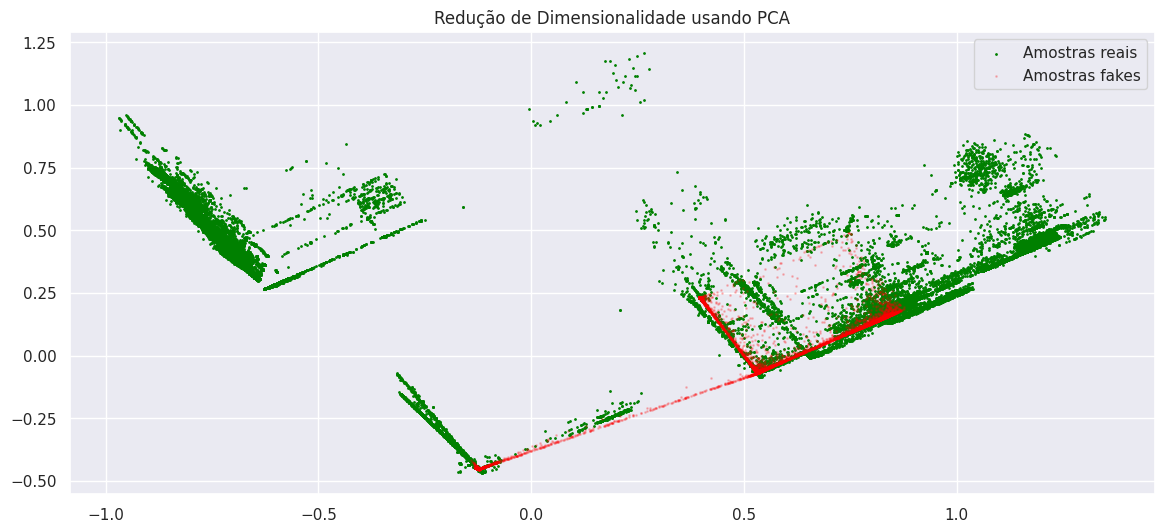

In [ ]:
plot_pca(norm_X_train_subset, norm_X_fake)

### Por que será que a GAN não conseguiu performar bem para gerar os dados?
<div align="center">

![thinking](https://i.pinimg.com/236x/a1/af/5e/a1af5eb72e73424b0afe12a777949464.jpg)
</div>



## Uma possível solução - WGAN com Gradient Penalty

A Wasserstein GAN é considerada como uma extensão da rede Generativa Adversarial introduzida por Ian Goodfellow. A WGAN foi introduzida por Martin Arjovsky em 2017 e promete melhorar tanto a estabilidade no treinamento do modelo quanto introduzir uma função de perda que seja capaz de se correlacionar com a qualidade dos eventos gerados.

Em vez de usar o conceito de "discriminador", a WGAN usa o conceito de "crítico", pois o mesmo vai fornecer como saída um número real qualquer, que não esteja delimitado em um intervalo que aponta o quanto as amostras geradas artificialmente são diferentes das reais, diferente do antigo discriminador, que fornecia saídas probabilistícas entre [0, 1]

**As principais diferenças introduzidas pela WGAN são**:

1. Usar uma nova função de perda derivada da distância de Wasserstein (WLoss).
2. Após cada atualização de gradiente na função crítica, fixar os pesos a uma pequena faixa fixa, [-c,c]. Isto permite aplicar a restrição de Lipschitz.
Alternativa proposta ao Discriminador — o Crítico.
3. Uso de uma função de ativação linear como a linear de saída da rede do Critic.
4. Número diferente de atualizações para o Gerador e para o crítico.

**Os principais benefícios da WGAN são**:
- Treinamento mais estável do que o da GAN tradicional
- Reduz os problemas de *mode collapse* da GAN tradicional
- Reduz o problema de *vanishing gradients* da GAN tradicional
- Menos sensível e impactada por hiperparâmetros e arquiteturas das redes do que a GAN tradicional


In [44]:
# Modulo "crítico"
class Critic(nn.Module):
  def __init__(self, tab_data_dim, lrelu_slope = 0.1):
    super().__init__()

    self.disc = nn.Sequential(
      nn.Linear(tab_data_dim, 120), # Layer 1
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(120, 80), # Layer 2
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(80, 1),
      # Percebam que não tem a função de ativação sigmoide
    )

  def forward(self, x):
    return self.disc(x)

class WGANGP(nn.Module):
  def __init__(self, z_dim, tab_data_dim, lrelu_slope=0.1, device = None):
    super().__init__()
    if not device:
      self.device = 'cuda' if torch.cuda.is_available() else 'cpu'

    self.z_dim = z_dim
    self.tab_data_dim = tab_data_dim
    self.lrelu_slope = lrelu_slope

    self.critic = Critic(self.tab_data_dim, self.lrelu_slope).to(self.device)
    self.generator = Generator(self.z_dim, tab_data_dim, self.lrelu_slope).to(self.device)

    # Opcional: usado para testes
    self.fixed_noise = None
    self.step = 0

  def compile(self, lr):
    assert self.critic and self.generator, 'Critic and generator must be initialized before using compile method.'

    self.optim_critic = optim.Adam(self.critic.parameters(), lr=lr)
    self.optim_generator = optim.Adam(self.generator.parameters(), lr=lr)

  # Uma das diferenças da WGAN
  def gradient_penalty(self, real, fake):
    batch_size = real.shape[0]
    epsilon = torch.rand(real.shape).to(self.device)
    interpolated_data = real*epsilon + (1 - epsilon)*fake

    # Calcular escores da imagem interpolada usando o crítico
    interpolated_scores = self.critic(interpolated_data)

    # Calcular o gradiente dos escores da imagem interpolada
    gradient = torch.autograd.grad(
        inputs = interpolated_data,
        outputs = interpolated_scores,
        grad_outputs = torch.ones_like(interpolated_scores),
        create_graph = True,
        retain_graph = True
    )[0]

    gradient = gradient.view(len(gradient), -1)
    gradient_norm = gradient.norm(2, dim=1)
    gradient_penalty = torch.mean((gradient_norm - 1)**2)
    return gradient_penalty

  def fit(self, X, batch_size, num_epochs, critic_iterations=5, lambda_gp = 0.05):
    assert self.optim_critic and self.optim_generator, 'Compile method must be called before using fit method.'

    # Opcional: usado apenas para testes
    if self.fixed_noise is None:
      self.fixed_noise = torch.randn((8, self.z_dim)).to(self.device)

    for epoch in range(num_epochs):
      print(f'Epoch#{epoch}')
      for batch in tqdm(range(0, len(X), batch_size)):
        real = X[batch:batch+batch_size]
        real = real.view(-1, self.tab_data_dim).to(self.device)
        curr_batch_size = real.shape[0]

        # Treinar o critico: maximizar a Earth's Mover Distance (ou minimizar o oposto da mesma)
        for _ in range(critic_iterations):
          noise = torch.randn(curr_batch_size, self.z_dim).to(self.device)
          fake = self.generator(noise)

          critic_real_output = self.critic(real).view(-1)
          critic_fake_output = self.critic(fake).view(-1)

          gp = self.gradient_penalty(real, fake)
          lossC = -(torch.mean(critic_real_output) - torch.mean(critic_fake_output)) + lambda_gp*gp
          self.critic.zero_grad()
          lossC.backward(retain_graph=True) # Para manter os gradientes para otimizar o generator
          self.optim_critic.step()

        # Treinar o gerador para minimzar log(1 - D(G(z))) <-> maximizar log(D(G(z)))
        output = self.critic(fake).view(-1)
        lossG = -torch.mean(output)
        self.generator.zero_grad()
        lossG.backward()
        self.optim_generator.step()

      print(
        f"Epoch [{epoch+1}/{num_epochs}] - Last Loss C: {lossC:.4f}, Last Loss G: {lossG:.4f}"
      )

In [53]:
wgangp = WGANGP(z_dim=Z_DIM, tab_data_dim=TAB_DATA_DIM)
wgangp.compile(lr=LR)
print(f'device: {wgangp.device}')
wgangp.fit(X=torch.tensor(norm_X_train, dtype=torch.float), batch_size=BATCH_SIZE, num_epochs=5)

device: cuda
Epoch#0


ImportError: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html

In [ ]:

torch.save(gan, 'wgan_model.pt')
# files.download('wgan_model.pt')

In [ ]:
# ---> Rode essa célula para baixar modelo pré-treinado

!gdown '1IAR0enh4KrRdPzK5hjcbpEpMnKI-lhry' -O 'pretrained_wgangp.pt'
wgangp = torch.load('pretrained_wgangp.pt', weights_only=False)

Downloading...
From: https://drive.google.com/uc?id=1IAR0enh4KrRdPzK5hjcbpEpMnKI-lhry
To: /content/pretrained_wgangp.pt
100% 404k/404k [00:00<00:00, 5.29MB/s]


### Gerando dados artificialmente

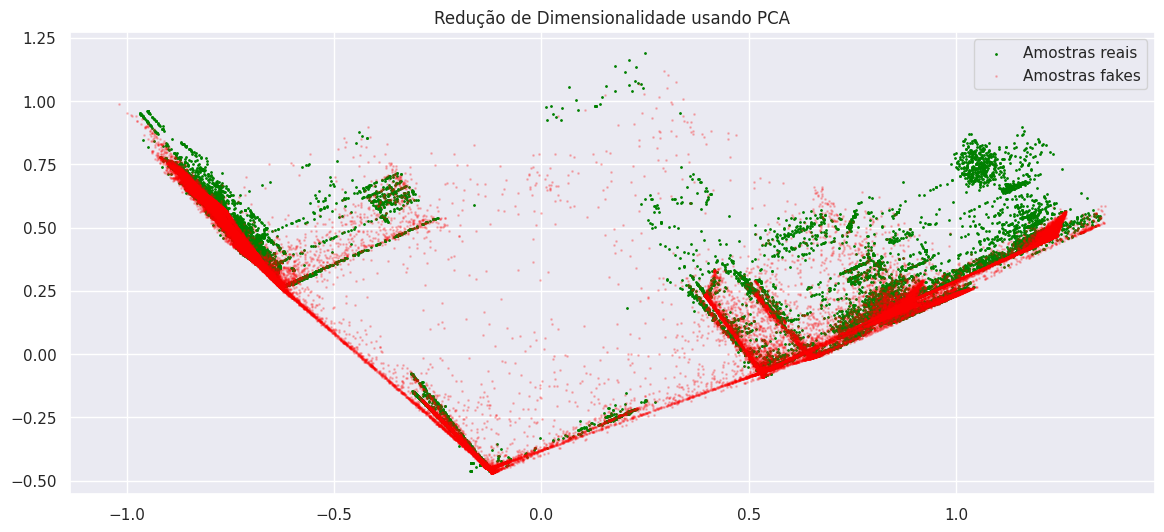

In [ ]:
QTD_INSTANCES = 100000

noises = torch.randn(QTD_INSTANCES, wgangp.z_dim).to(wgangp.device)
norm_X_wgangp_fake = wgangp.generator(noises).cpu().detach().numpy()

random_train_indexes = np.random.choice(norm_X_train.shape[0], QTD_INSTANCES, replace=False)
norm_X_train_subset = norm_X_train[random_train_indexes,:]

plot_pca(norm_X_train_subset, norm_X_wgangp_fake)

# Definindo um threshold e avaliando resultados

In [ ]:
def plot_roc_curve(y_true, y_score, max_fpr=1.0):
  fpr, tpr, thresholds = roc_curve(y_true, y_score)
  aucroc = roc_auc_score(y_true, y_score)
  plt.plot(100*fpr[fpr < max_fpr], 100*tpr[fpr < max_fpr], label=f'ROC Curve (AUC = {aucroc:.4f})')
  plt.xlim(-2,102)
  plt.xlabel('FPR (%)')
  plt.ylabel('TPR (%)')
  plt.legend()
  plt.title('ROC Curve and AUCROC')

In [ ]:
def get_tpr_per_attack(y_labels, y_pred):
  aux_df = pd.DataFrame({'Label':y_labels,'prediction':y_pred})
  total_per_label = aux_df['Label'].value_counts().to_dict()
  correct_predictions_per_label = aux_df.query('Label != "BENIGN" and prediction == True').groupby('Label').size().to_dict()
  tpr_per_attack = {}
  for attack_label, total in total_per_label.items():
    if attack_label == 'BENIGN':
      continue
    tp = correct_predictions_per_label[attack_label] if attack_label in correct_predictions_per_label else 0
    tpr = tp/total
    tpr_per_attack[attack_label] = tpr
  return tpr_per_attack

In [ ]:
def get_overall_metrics(y_true, y_pred):
  tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
  acc = (tp+tn)/(tp+tn+fp+fn)
  tpr = tp/(tp+fn)
  fpr = fp/(fp+tn)
  precision = tp/(tp+fp)
  f1 = (2*tpr*precision)/(tpr+precision)
  return {'acc':acc,'tpr':tpr,'fpr':fpr,'precision':precision,'f1-score':f1}

In [ ]:
def plot_confusion_matrix(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  group_counts = [f'{value:.0f}' for value in confusion_matrix(y_true, y_pred).ravel()]
  group_percentages = [f'{value*100:.2f}%' for value in confusion_matrix(y_true, y_pred).ravel()/np.sum(cm)]
  labels = [f'{v1}\n{v2}' for v1, v2 in zip(group_counts, group_percentages)]
  labels = np.array(labels).reshape(2,2)
  sns.heatmap(cm, annot=labels, cmap='Oranges', xticklabels=['Predicted Benign', 'Predicted Malicious'], yticklabels=['Actual Benign', 'Actual Malicious'], fmt='')
  return

## Conjunto de validação - GAN Tradicional

In [ ]:
val_scores_gan = gan.discriminator(torch.tensor(norm_X_val, dtype=torch.float).to(gan.device))
val_scores_gan = val_scores_gan.cpu().detach().numpy()

anomaly_score_gan = 1 - val_scores_gan # Pois a saida do discriminador da GAN aponta a probabilidade de uma instância ser REAL (benigna). Podemos estimar a probabilidade da instância x ser maliciosa com 1 - D(x)

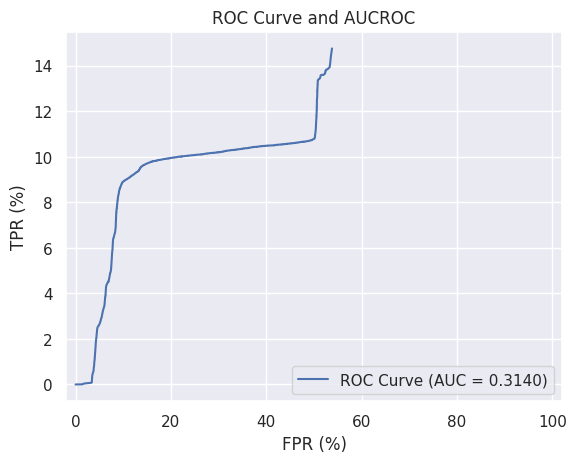

In [ ]:
plot_roc_curve(y_val, anomaly_score_gan)

In [ ]:
fpr, tpr, thresholds = roc_curve(y_val, anomaly_score_gan)
df_val_roc = pd.DataFrame({'fpr':fpr, 'tpr':tpr, 'thresholds':thresholds})
df_val_roc['youden-index'] = df_val_roc['tpr'] - df_val_roc['fpr']
df_val_roc.sort_values('youden-index', ascending=False).drop_duplicates('fpr').query('fpr < 0.4')

,fpr,tpr,thresholds,youden-index
0,0.000000,0.000000,inf,0.000000
1,0.000003,0.000000,0.999996,-0.000003
2,0.000014,0.000000,0.999993,-0.000014
3,0.000020,0.000000,0.999992,-0.000020
4,0.000041,0.000000,0.999990,-0.000041
...,...,...,...,...
36684,0.399933,0.104853,0.952280,-0.295080
36685,0.399940,0.104853,0.952280,-0.295087
36686,0.399971,0.104853,0.952276,-0.295117
36687,0.399978,0.104853,0.952276,-0.295124


In [ ]:
GAN_BEST_VALIDATION_THRESHOLD = 0.736793

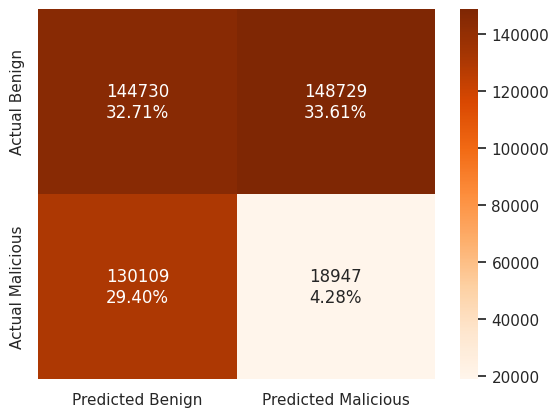

In [ ]:
plot_confusion_matrix(y_val, anomaly_score_gan > GAN_BEST_VALIDATION_THRESHOLD)

In [ ]:
get_overall_metrics(y_val, val_scores_gan > GAN_BEST_VALIDATION_THRESHOLD)

{'acc': np.float64(0.629465667830469),
 'tpr': np.float64(0.8660167990553885),
 'fpr': np.float64(0.49068524052763757),
 'precision': np.float64(0.47269857661279985),
 'f1-score': np.float64(0.6115787054913452)}

In [ ]:
get_tpr_per_attack(classes_val, (val_scores_gan > GAN_BEST_VALIDATION_THRESHOLD)[:,0])

{'DoS Hulk': 0.9480626818302037,
 'DDoS': 0.6394679284024462,
 'PortScan': 0.9994022713687986,
 'DoS GoldenEye': 0.8205555555555556,
 'FTP-Patator': 0.9985549132947977,
 'DoS slowloris': 0.9994694960212201,
 'DoS Slowhttptest': 1.0,
 'SSH-Patator': 0.9982253771073647,
 'Bot': 0.9956076134699854,
 'Web Attack � Brute Force': 1.0,
 'Web Attack � XSS': 0.9956140350877193,
 'Infiltration': 1.0,
 'Web Attack � Sql Injection': 1.0,
 'Heartbleed': 1.0}

## Conjunto de validação - WGANGP

In [ ]:
val_scores_wgangp = wgangp.critic(torch.tensor(norm_X_val, dtype=torch.float).to(wgangp.device))
val_scores_wgangp = val_scores_wgangp.cpu().detach().numpy()

anomaly_score_wgangp = -val_scores_wgangp

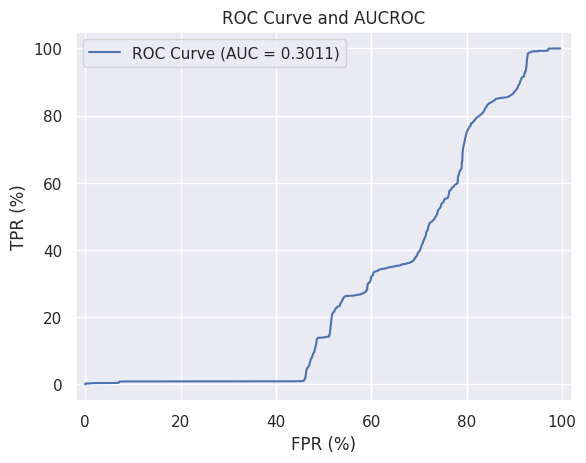

In [ ]:
plot_roc_curve(y_val, anomaly_score_wgangp)

In [ ]:
fpr, tpr, thresholds = roc_curve(y_val, anomaly_score_wgangp)
df_val_roc = pd.DataFrame({'fpr':fpr, 'tpr':tpr, 'thresholds':thresholds})
df_val_roc['youden-index'] = df_val_roc['tpr'] - df_val_roc['fpr']
df_val_roc.sort_values('youden-index', ascending=False).drop_duplicates('fpr').query('fpr < 0.15')

,fpr,tpr,thresholds,youden-index
33,0.000000,0.002516,1.101806,0.002516
34,0.001513,0.002516,0.847640,0.001003
35,0.001520,0.002516,0.847556,0.000996
37,0.001864,0.002523,0.840036,0.000659
39,0.003483,0.002529,0.822606,-0.000953
...,...,...,...,...
8260,0.149956,0.009117,0.747214,-0.140839
8261,0.149966,0.009117,0.747213,-0.140849
8262,0.149973,0.009117,0.747213,-0.140856
8263,0.149987,0.009117,0.747213,-0.140870


In [ ]:
# WGANGP_BEST_VALIDATION_THRESHOLD = 0.250968
WGANGP_BEST_VALIDATION_THRESHOLD = 0.330715

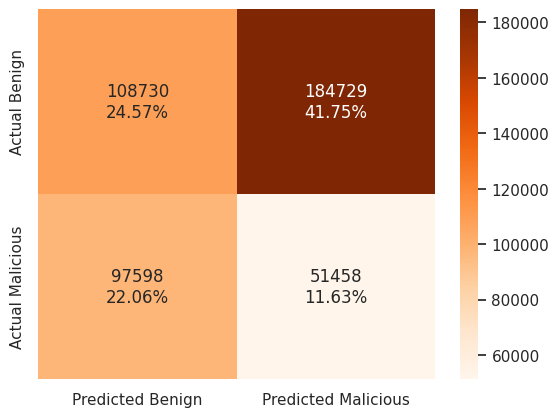

In [ ]:
plot_confusion_matrix(y_val, anomaly_score_wgangp > WGANGP_BEST_VALIDATION_THRESHOLD)

In [ ]:
get_overall_metrics(y_val, anomaly_score_wgangp > WGANGP_BEST_VALIDATION_THRESHOLD)

{'acc': np.float64(0.36199450866072336),
 'tpr': np.float64(0.34522595534564193),
 'fpr': np.float64(0.629488276045376),
 'precision': np.float64(0.21786973880865584),
 'f1-score': np.float64(0.2671456716929315)}

In [ ]:
get_tpr_per_attack(classes_val, (anomaly_score_wgangp > WGANGP_BEST_VALIDATION_THRESHOLD)[:,0])

{'DoS Hulk': 0.1457286432160804,
 'DDoS': 0.8538365397491408,
 'PortScan': 0.011860194419102148,
 'DoS GoldenEye': 0.6,
 'FTP-Patator': 0.33140655105973027,
 'DoS slowloris': 0.2774535809018568,
 'DoS Slowhttptest': 0.14043715846994537,
 'SSH-Patator': 0.07630878438331855,
 'Bot': 0.3513909224011713,
 'Web Attack � Brute Force': 0.07976653696498054,
 'Web Attack � XSS': 0.02631578947368421,
 'Infiltration': 0.23076923076923078,
 'Web Attack � Sql Injection': 0.5714285714285714,
 'Heartbleed': 0.0}

## Conjunto de teste - GAN Tradicional

In [ ]:
test_scores_gan = gan.discriminator(torch.tensor(norm_X_test, dtype=torch.float).to(gan.device))
test_scores_gan = test_scores_gan.cpu().detach().numpy()

test_anomaly_scores_gan = 1 - test_scores_gan

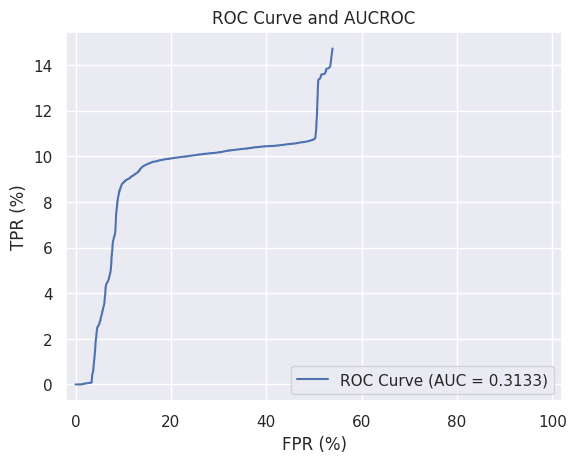

In [ ]:
plot_roc_curve(y_test, test_anomaly_scores_gan)

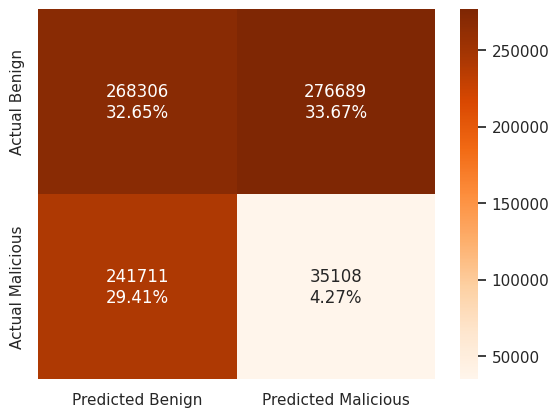

In [ ]:
plot_confusion_matrix(y_test, test_anomaly_scores_gan > GAN_BEST_VALIDATION_THRESHOLD)

In [ ]:
get_overall_metrics(y_test, test_anomaly_scores_gan > GAN_BEST_VALIDATION_THRESHOLD)

{'acc': np.float64(0.36920033000167923),
 'tpr': np.float64(0.1268265545356352),
 'fpr': np.float64(0.5076908962467546),
 'precision': np.float64(0.11259890249104386),
 'f1-score': np.float64(0.11928999551490277)}

In [ ]:
get_tpr_per_attack(classes_test, (test_anomaly_scores_gan > GAN_BEST_VALIDATION_THRESHOLD)[:,0])

{'DoS Hulk': 0.051971517578994215,
 'DDoS': 0.3373993510395385,
 'PortScan': 0.0007284184848895515,
 'DoS GoldenEye': 0.16556984744241698,
 'FTP-Patator': 0.00155561317085818,
 'DoS slowloris': 0.0005714285714285715,
 'DoS Slowhttptest': 0.0,
 'SSH-Patator': 0.0033460803059273425,
 'Bot': 0.008661417322834646,
 'Web Attack � Brute Force': 0.0,
 'Web Attack � XSS': 0.03773584905660377,
 'Infiltration': 0.08695652173913043,
 'Web Attack � Sql Injection': 0.0,
 'Heartbleed': 0.0}

## Conjunto de teste - WGANGP

In [ ]:
test_scores_wgangp = wgangp.critic(torch.tensor(norm_X_test, dtype=torch.float).to(wgangp.device))
test_scores_wgangp = test_scores_wgangp.cpu().detach().numpy()

test_anomaly_scores_wgapgp = -test_scores_wgangp

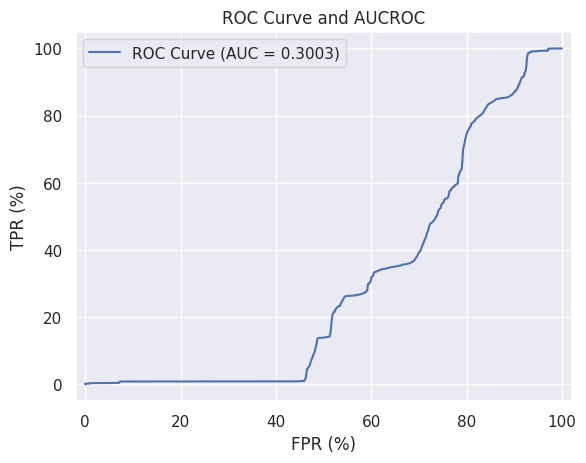

In [ ]:
plot_roc_curve(y_test, test_anomaly_scores_wgapgp)

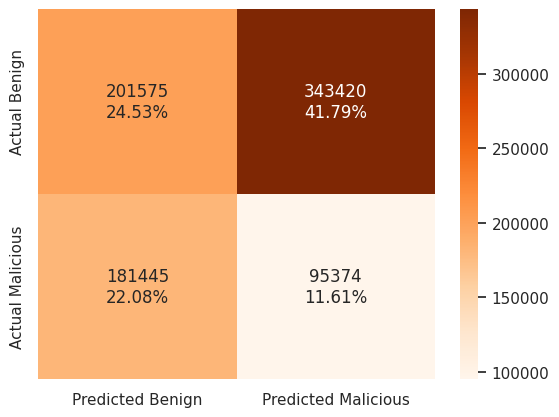

In [ ]:
plot_confusion_matrix(y_test, test_anomaly_scores_wgapgp > WGANGP_BEST_VALIDATION_THRESHOLD)

In [ ]:
get_overall_metrics(y_test, test_anomaly_scores_wgapgp > WGANGP_BEST_VALIDATION_THRESHOLD)

{'acc': np.float64(0.36133358643196634),
 'tpr': np.float64(0.344535599073763),
 'fpr': np.float64(0.6301342214148754),
 'precision': np.float64(0.2173548407681053),
 'f1-score': np.float64(0.26655189327192214)}

In [ ]:
get_tpr_per_attack(classes_test, (test_anomaly_scores_wgapgp > WGANGP_BEST_VALIDATION_THRESHOLD)[:,0])

{'DoS Hulk': 0.14510903426791277,
 'DDoS': 0.8516524456195169,
 'PortScan': 0.01277273343271446,
 'DoS GoldenEye': 0.6042476817230032,
 'FTP-Patator': 0.3290121856365051,
 'DoS slowloris': 0.26914285714285713,
 'DoS Slowhttptest': 0.13655091230135374,
 'SSH-Patator': 0.0731357552581262,
 'Bot': 0.38346456692913383,
 'Web Attack � Brute Force': 0.06799163179916318,
 'Web Attack � XSS': 0.04245283018867924,
 'Infiltration': 0.30434782608695654,
 'Web Attack � Sql Injection': 0.35714285714285715,
 'Heartbleed': 0.14285714285714285}

# Perguntas

O conceito básico é treinar a GAN em dados normais para que ela aprenda a reproduzir padrões típicos desse conjunto de dados. Quando a GAN é confrontada com dados que diferem significativamente do padrão normal, ela pode ter dificuldade em gerar algo semelhante, e essas discrepâncias podem ser usadas para detectar anomalias.

## 1. Através da redução de dimensionalidade, é possível observar que os dados gerados pela GAN tradicional possuem uma diferença para os dados gerados pela WGAN. O que você observou como diferente nos dados gerados pela WGAN? Por que isso aconteceu?

A WGAN consegue gerar dados de padrões de dados vistos no treinamento mais diversos do que a GAN tradicional.

Isso ocorre pois a WGAN consegue reduzir o problema de "mode collapse" que ocorre principalmente na GAN tradicional. A WGAN consegue fazer isso com as suas mudanças na função loss, troca do discriminador pelo crítico, aproximação a uma função lipschitz contínua, etc.

## 2. Explique possíveis razões para que a WGAN deu melhores resultados para detecção de anomalias em comparação com a GAN tradicional.

Visto que a WGAN conseguiu gerar padrões mais diversos, o crítico da WGAN realizou um treinamento mais efetivo para que o mesmo conseguisse separar os exemplos reais (benignos) dos falsos (criados pelo gerador). Visto que o gerador da WGAN é mais robusto, o discriminador também tende a ser mais robusto devido ao treinamento adversarial das duas redes.

# Atividade de código

## Refaça o código da WGAN com Gradient Penalty considerando que as redes do discriminador e gerador tenham apenas UMA camada interna antes da camada de saída e avalie os resultados

In [ ]:
class Generator(nn.Module):
  def __init__(self, z_dim, tab_data_dim, lrelu_slope = 0.1):
    super().__init__()

    self.gen = nn.Sequential(
      nn.Linear(z_dim, 100), # Layer 1
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(100, tab_data_dim),
      nn.Sigmoid() # Para garantir que a saída dos valores tabulares está em ]0, 1[
    )

  def forward(self, x):
    return self.gen(x)

class Critic(nn.Module):
  def __init__(self, tab_data_dim, lrelu_slope = 0.1):
    super().__init__()

    self.disc = nn.Sequential(
      nn.Linear(tab_data_dim, 120), # Layer 1
      nn.LeakyReLU(lrelu_slope),
      nn.Linear(80, 1),
    )

  def forward(self, x):
    return self.disc(x)

class NEW_WGANGP(nn.Module):
  def __init__(self, z_dim, tab_data_dim, lrelu_slope=0.1, device = None):
    super().__init__()
    if not device:
      self.device = 'cuda' if torch.cuda.is_available() else 'cpu'

    self.z_dim = z_dim
    self.tab_data_dim = tab_data_dim
    self.lrelu_slope = lrelu_slope

    self.critic = Critic(self.tab_data_dim, self.lrelu_slope).to(self.device)
    self.generator = Generator(self.z_dim, tab_data_dim, self.lrelu_slope).to(self.device)

    # Opcional: usado para testes
    self.fixed_noise = None
    self.step = 0

  def compile(self, lr):
    assert self.critic and self.generator, 'Critic and generator must be initialized before using compile method.'

    self.optim_critic = optim.Adam(self.critic.parameters(), lr=lr)
    self.optim_generator = optim.Adam(self.generator.parameters(), lr=lr)

  def gradient_penalty(self, real, fake):
    batch_size = real.shape[0]
    epsilon = torch.rand(real.shape).to(self.device)
    interpolated_data = real*epsilon + (1 - epsilon)*fake

    # Calcular escores da imagem interpolada usando o crítico
    interpolated_scores = self.critic(interpolated_data)

    # Calcular o gradiente dos escores da imagem interpolada
    gradient = torch.autograd.grad(
        inputs = interpolated_data,
        outputs = interpolated_scores,
        grad_outputs = torch.ones_like(interpolated_scores),
        create_graph = True,
        retain_graph = True
    )[0]

    gradient = gradient.view(len(gradient), -1)
    gradient_norm = gradient.norm(2, dim=1)
    gradient_penalty = torch.mean((gradient_norm - 1)**2)
    return gradient_penalty

  def fit(self, X, batch_size, num_epochs, critic_iterations=5, lambda_gp = 0.05):
    assert self.optim_critic and self.optim_generator, 'Compile method must be called before using fit method.'

    # Opcional: usado apenas para testes
    if self.fixed_noise is None:
      self.fixed_noise = torch.randn((8, self.z_dim)).to(self.device)

    for epoch in range(num_epochs):
      print(f'Epoch#{epoch}')
      for batch in tqdm(range(0, len(X), batch_size)):
        real = X[batch:batch+batch_size]
        real = real.view(-1, self.tab_data_dim).to(self.device)
        curr_batch_size = real.shape[0]

        # Treinar o critico: maximizar a Earth's Mover Distance (ou minimizar o oposto da mesma)
        for _ in range(critic_iterations):
          noise = torch.randn(curr_batch_size, self.z_dim).to(self.device)
          fake = self.generator(noise)

          critic_real_output = self.critic(real).view(-1)
          critic_fake_output = self.critic(fake).view(-1)

          gp = self.gradient_penalty(real, fake)
          lossC = -(torch.mean(critic_real_output) - torch.mean(critic_fake_output)) + lambda_gp*gp
          self.critic.zero_grad()
          lossC.backward(retain_graph=True) # Para manter os gradientes para otimizar o generator
          self.optim_critic.step()

        # Treinar o gerador para minimzar log(1 - D(G(z))) <-> maximizar log(D(G(z)))
        output = self.critic(fake).view(-1)
        lossG = -torch.mean(output)
        self.generator.zero_grad()
        lossG.backward()
        self.optim_generator.step()

      print(
        f"Epoch [{epoch+1}/{num_epochs}] - Last Loss C: {lossC:.4f}, Last Loss G: {lossG:.4f}"
      )

In [ ]:
new_wgangp = NEW_WGANGP(z_dim=Z_DIM, tab_data_dim=TAB_DATA_DIM)
new_wgangp.compile(lr=LR)
print(f'device: {new_wgangp.device}')
new_wgangp.fit(X=torch.tensor(norm_X_train, dtype=torch.float), batch_size=BATCH_SIZE, num_epochs=4)